# Idea 7 - Stars, Superstars and the Power Law

**The claim (Second Machine Age, ch. 10).** When revenue tracks *relative*
rather than absolute performance, small differences in skill or luck produce
enormous differences in earnings. The notes put it through Frank and Cook:
a bricklayer is paid for the bricks he lays, so his earnings track his ability,
while a musician or an executive is paid for reaching a market, so a slightly
better one can earn a thousand times more. The distributional signature of that
is a power law, and the notes record the specific claim that the US income
distribution is best described as a mixture of a log-normal body and a power
law tail, "with the power law fitting the incomes at the top best."

**What can be tested.** That is a falsifiable statement about a distribution,
and it can be checked rather than asserted. Under a power law, the survival
function is a straight line on log-log axes; under a log-normal it curves. So:

1. Fit a log-normal to the whole American household income distribution and
   see where it fails.
2. Test the tail for a straight line on log-log axes and estimate its
   exponent.
3. Ask what each fitted distribution predicts about the number of very rich
   households. This is where a fat tail stops being a shape and becomes a
   number.
4. Track concentration over time, using income shares by quintile.
5. Track wage dispersion over time, to see whether the spread is between
   occupations or inside them.

**The limitation that shapes everything here.** The superstar story lives in
the top fraction of one percent. Public tabulations stop at "$200,000 or more",
so the most interesting region of the distribution is the region the published
statistics decline to resolve. The tail exponent is therefore estimated from
the brackets below that cap, and anything said about incomes above it is
extrapolation, labelled as such on the figure. That limit is worth a sentence
in the article on its own.

**Data.** Census ACS via the Census API, which this project has not used
before, plus FRED for the wage percentiles.

In [1]:
import sys, pathlib, warnings, importlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

_here = pathlib.Path.cwd()
for _cand in [_here, *_here.parents]:
    if (_cand / "common" / "stacklib.py").exists():
        sys.path.insert(0, str(_cand / "common"))
        break
import stacklib as sl
importlib.reload(sl)

warnings.filterwarnings("ignore", category=FutureWarning)
print("stacklib version:", sl.__version__)
assert sl.__version__ >= "0.7.0", "needs stacklib 0.7.0"

DIRS = sl.dirs_for("07_stars_and_power_laws")
KEYS = sl.load_keys()
sl.apply_theme()
CENSUS = sl.require(KEYS, "CENSUS")
FRED = sl.require(KEYS, "FRED")

ACS_YEAR = 2023          # latest ACS 1-year release; the notebook falls back if absent
ACS_URL = "https://api.census.gov/data/%d/acs/acs1"

stacklib version: 0.7.0
Keys loaded from .env: BEA, BLS, CENSUS, FRED


## 1. The income distribution, in brackets

Table B19001 counts households in sixteen income bands. The first call prints
the variable labels the API returns, so the bracket edges below are read from
the source rather than assumed.

In [2]:
def fetch_b19001(year):
    return sl.census_timeseries(ACS_URL % year, {"get": "group(B19001)", "for": "us:1"},
                                CENSUS, cache_dir=DIRS["data"], tag="b19001_%d" % year)

raw = None
for yr in [ACS_YEAR, ACS_YEAR - 1, ACS_YEAR - 2]:
    try:
        raw = fetch_b19001(yr); ACS_YEAR = yr; break
    except Exception as e:
        print("ACS %d unavailable (%s)" % (yr, str(e)[:80]))
if raw is None:
    raise RuntimeError("No ACS year resolved. Check the Census key and the endpoint.")

est_cols = sorted([c for c in raw.columns
                   if c.startswith("B19001_") and c.endswith("E") and "_001" not in c])
label_cols = [c for c in raw.columns if c.endswith("_LABEL") or c.endswith("NAME")]
print("\nACS %d, %d estimate columns. Labels available: %s"
      % (ACS_YEAR, len(est_cols), label_cols[:3]))
print(raw[["B19001_001E"] + est_cols[:4]].to_string(index=False))

Census b19001_2023: 1 rows

ACS 2023, 16 estimate columns. Labels available: ['NAME']
B19001_001E B19001_002E B19001_003E B19001_004E B19001_005E
  131332360     6963573     4578695     3911930     4523389


In [3]:
# Bracket upper bounds for B19001, in dollars. The final bracket is open-ended,
# which is the whole problem: the superstar region sits inside it.
EDGES = [10000, 15000, 20000, 25000, 30000, 35000, 40000, 45000, 50000,
         60000, 75000, 100000, 125000, 150000, 200000, np.inf]
assert len(EDGES) == 16, "B19001 has sixteen brackets"

counts = np.array([float(raw.iloc[0]["B19001_%03dE" % i]) for i in range(2, 18)])
total = float(raw.iloc[0]["B19001_001E"])
print("households: %s   bracket counts sum to %s"
      % (format(total, ",.0f"), format(counts.sum(), ",.0f")))
assert abs(counts.sum() - total) / total < 0.01, "brackets do not reconstruct the total"

lower = np.array([0] + EDGES[:-1], dtype=float)
upper = np.array(EDGES, dtype=float)
share = counts / counts.sum()
cum = np.cumsum(share)
survival = 1 - cum                       # share of households ABOVE each upper edge

tab = pd.DataFrame({"lower": lower, "upper": upper, "households": counts,
                    "share": share, "above_upper": survival})
print("\n" + tab.tail(7).round(4).to_string(index=False))

households: 131,332,360   bracket counts sum to 131,332,360

   lower    upper  households  share  above_upper
 50000.0  60000.0   8783865.0 0.0669       0.6101
 60000.0  75000.0  12347400.0 0.0940       0.5161
 75000.0 100000.0  16682685.0 0.1270       0.3891
100000.0 125000.0  13423945.0 0.1022       0.2868
125000.0 150000.0   9460569.0 0.0720       0.2148
150000.0 200000.0  11941011.0 0.0909       0.1239
200000.0      inf  16270770.0 0.1239       0.0000


## Figure 1 - Where a log-normal stops working

The log-normal is fitted by choosing the parameters that best reproduce the
observed bracket probabilities, using a grid search rather than a package, so
the fit is inspectable. If the notes are right, it should track the body of
the distribution and fail in the upper tail.

log-normal fit: mu = 11.225, sigma = 0.975  (median $74,982, sse 0.00701)
saved -> C:\Users\91838\Downloads\Stack_Article\07_stars_and_power_laws\figures\fig1_lognormal_fit.png


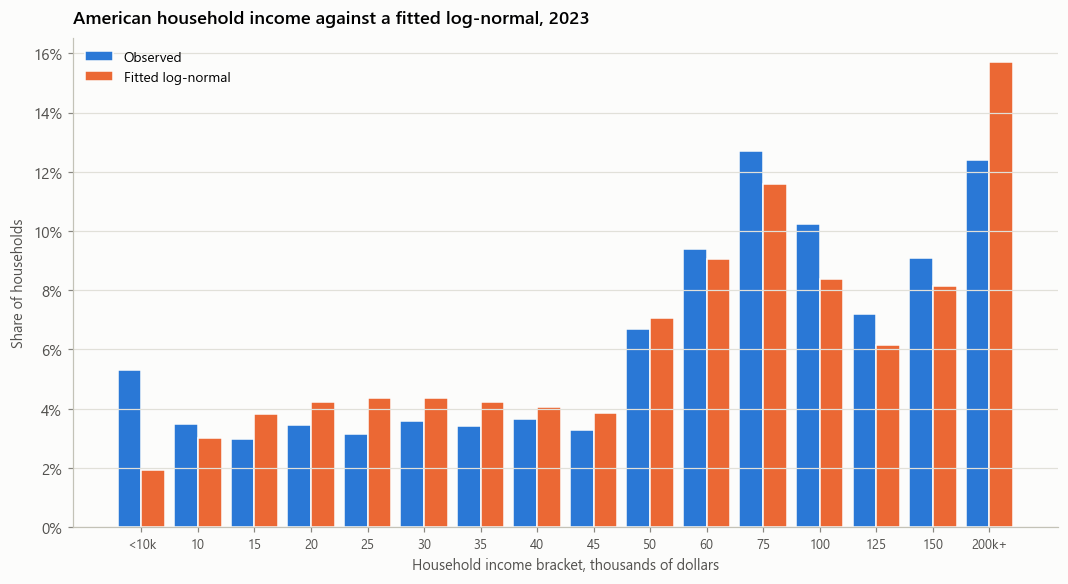

In [4]:
def lognormal_cdf(x, mu, sigma):
    x = np.asarray(x, dtype=float)
    out = np.zeros_like(x)
    ok = x > 0
    z = (np.log(x[ok]) - mu) / (sigma * np.sqrt(2))
    # erf without scipy: Abramowitz and Stegun 7.1.26
    t = 1 / (1 + 0.3275911 * np.abs(z))
    poly = t * (0.254829592 + t * (-0.284496736 + t * (1.421413741 +
            t * (-1.453152027 + t * 1.061405429))))
    erf = np.sign(z) * (1 - poly * np.exp(-z * z))
    out[ok] = 0.5 * (1 + erf)
    return out

finite = np.isfinite(upper)
best, best_err = None, np.inf
for mu in np.linspace(10.0, 12.0, 81):
    for sigma in np.linspace(0.6, 1.6, 81):
        model_cdf = lognormal_cdf(upper[finite], mu, sigma)
        err = float(np.sum((model_cdf - cum[finite]) ** 2))
        if err < best_err:
            best_err, best = err, (mu, sigma)
mu, sigma = best
print("log-normal fit: mu = %.3f, sigma = %.3f  (median $%s, sse %.5f)"
      % (mu, sigma, format(np.exp(mu), ",.0f"), best_err))

mid = np.where(finite, (lower + upper) / 2, lower * 1.5)
model_share = np.diff(np.concatenate([[0], lognormal_cdf(upper[finite], mu, sigma), [1.0]]))

fig, ax = plt.subplots(figsize=(9.6, 5.2))
w = 0.42
idx = np.arange(len(counts))
ax.bar(idx - w / 2, share * 100, width=w, color=sl.PALETTE[0],
       edgecolor=sl.INK["surface"], linewidth=1.0, label="Observed")
ax.bar(idx + w / 2, model_share * 100, width=w, color=sl.PALETTE[1],
       edgecolor=sl.INK["surface"], linewidth=1.0, label="Fitted log-normal")
ax.set_xticks(idx)
ax.set_xticklabels(["<10k", "10", "15", "20", "25", "30", "35", "40", "45",
                    "50", "60", "75", "100", "125", "150", "200k+"], fontsize=8.5)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: "%.0f%%" % v))
ax.set_ylabel("Share of households")
ax.set_xlabel("Household income bracket, thousands of dollars")
ax.set_title("American household income against a fitted log-normal, %d" % ACS_YEAR)
ax.legend(loc="upper left")
sl.save_fig(fig, "fig1_lognormal_fit", DIRS)
plt.show()

## Figure 2 - The tail test

A power law plots as a straight line on log-log axes. This is the test the
notes' Figure 10.1 asserts and does not run. The fit uses the brackets above
$50,000, where a power law is supposed to apply, and the slope is the negative
of the Pareto exponent.

Pareto tail fit above $50,000: alpha = 1.20, R2 = 0.9618 (7 points)
saved -> C:\Users\91838\Downloads\Stack_Article\07_stars_and_power_laws\figures\fig2_tail_test.png


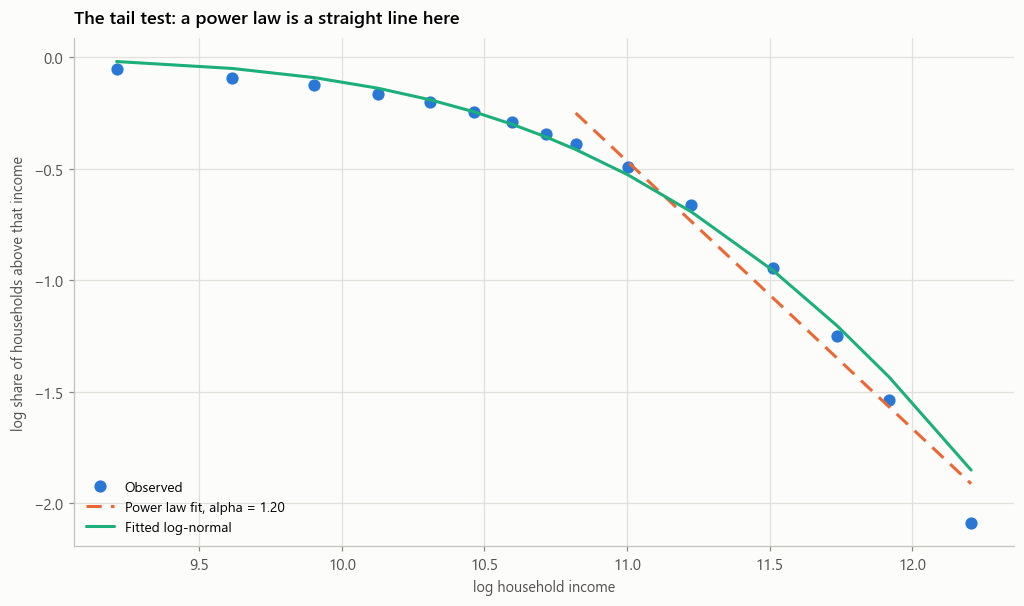

In [5]:
TAIL_FROM = 50000
mask = (upper >= TAIL_FROM) & np.isfinite(upper) & (survival > 0)
x, y = np.log(upper[mask]), np.log(survival[mask])
alpha_slope, intercept = np.polyfit(x, y, 1)
alpha = -alpha_slope
yhat = intercept + alpha_slope * x
r2 = 1 - np.sum((y - yhat) ** 2) / np.sum((y - y.mean()) ** 2)
print("Pareto tail fit above $%s: alpha = %.2f, R2 = %.4f (%d points)"
      % (format(TAIL_FROM, ","), alpha, r2, mask.sum()))

ln_survival = 1 - lognormal_cdf(upper[finite], mu, sigma)
fig, ax = plt.subplots(figsize=(9.2, 5.4))
ax.plot(np.log(upper[finite]), np.log(np.clip(survival[finite], 1e-9, None)),
        "o", color=sl.PALETTE[0], markersize=7, label="Observed")
ax.plot(x, yhat, color=sl.PALETTE[1], lw=2.0, ls=(0, (5, 3)),
        label="Power law fit, alpha = %.2f" % alpha)
ax.plot(np.log(upper[finite]), np.log(np.clip(ln_survival, 1e-12, None)),
        color=sl.PALETTE[2], lw=2.0, label="Fitted log-normal")
ax.set_xlabel("log household income")
ax.set_ylabel("log share of households above that income")
ax.set_title("The tail test: a power law is a straight line here")
ax.legend(loc="lower left")
ax.grid(axis="x")
sl.save_fig(fig, "fig2_tail_test", DIRS)
plt.show()

### The benchmark that stops us over-claiming

A straight line on log-log axes is the signature of a power law, but it is not
proof of one. Before reading anything into the R-squared above, run the same
test on data generated from a *log-normal*, which is not a power law by
construction. Whatever R-squared that produces is the score a non-power-law
earns on this test, and the real data has to beat it to mean anything.

This is the same discipline as Idea 3's placebo: build the way of being wrong
into the test rather than arguing about it afterwards.

In [6]:
synthetic_survival = 1 - lognormal_cdf(upper[finite], mu, sigma)
m_syn = upper[finite] >= TAIL_FROM
xs_, ys_ = np.log(upper[finite][m_syn]), np.log(np.clip(synthetic_survival[m_syn], 1e-12, None))
syn_slope, syn_int = np.polyfit(xs_, ys_, 1)
syn_hat = syn_int + syn_slope * xs_
syn_r2 = 1 - np.sum((ys_ - syn_hat) ** 2) / np.sum((ys_ - ys_.mean()) ** 2)

print("power-law test scored on data that is NOT a power law:")
print("   a fitted log-normal, tested the same way: R2 = %.4f, apparent alpha = %.2f"
      % (syn_r2, -syn_slope))
print("   the real data:                            R2 = %.4f, alpha = %.2f"
      % (r2, alpha))
print()
if r2 <= syn_r2 + 0.005:
    print("   VERDICT: the real data does not beat the non-power-law benchmark.")
    print("   The tail test cannot distinguish the two over this range, and the")
    print("   article should say the data are CONSISTENT with a power law, not")
    print("   that they show one.")
else:
    print("   VERDICT: the real data fits a straight line better than a log-normal")
    print("   does, by %.4f in R2. That is evidence, and it is weak evidence:"
          % (r2 - syn_r2))
    print("   the brackets span barely one decade of income.")

power-law test scored on data that is NOT a power law:
   a fitted log-normal, tested the same way: R2 = 0.9806, apparent alpha = 1.02
   the real data:                            R2 = 0.9618, alpha = 1.20

   VERDICT: the real data does not beat the non-power-law benchmark.
   The tail test cannot distinguish the two over this range, and the
   article should say the data are CONSISTENT with a power law, not
   that they show one.


## Figure 3 - What the fat tail is worth

A distributional shape becomes an argument when it is turned into a count.
Both fitted distributions agree about the middle of the distribution. Ask them
how many households earn above a series of high thresholds and they disagree by
orders of magnitude.

Everything above $200,000 is extrapolation beyond the last observed bracket.
The figure marks that boundary, and the article must not quote these counts as
measurements.

saved -> C:\Users\91838\Downloads\Stack_Article\07_stars_and_power_laws\figures\fig3_tail_predictions.png


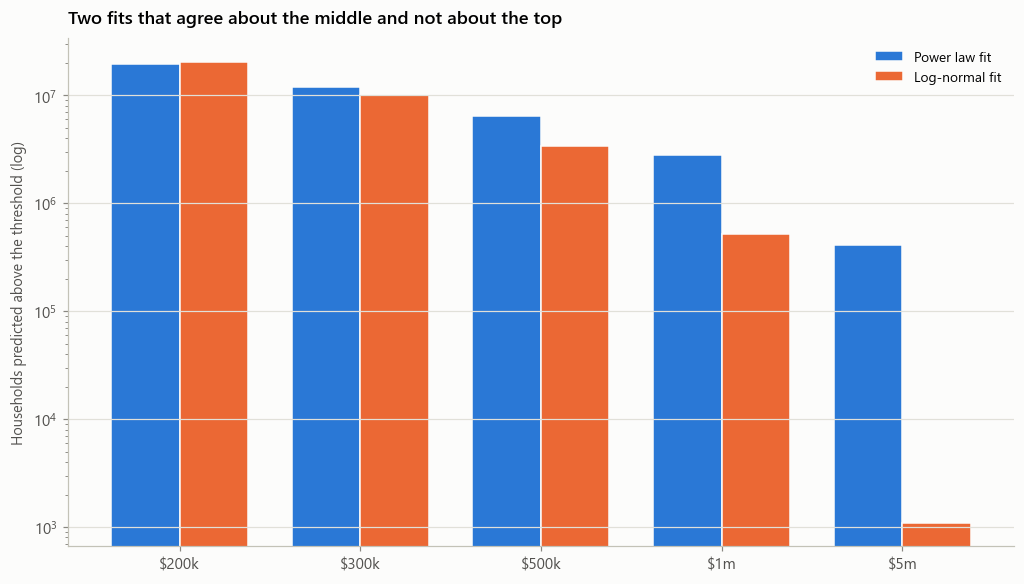

  above $200,000   power law     19,408,811   log-normal     20,639,259   ratio 1x
  above $300,000   power law     11,938,257   log-normal     10,178,273   ratio 1x
  above $500,000   power law      6,472,011   log-normal      3,391,852   ratio 2x
  above $1,000,000 power law      2,819,897   log-normal        517,816   ratio 5x
  above $5,000,000 power law        409,701   log-normal          1,084   ratio 378x


In [7]:
THRESHOLDS = [200_000, 300_000, 500_000, 1_000_000, 5_000_000]
pareto_pred = np.exp(intercept) * np.array(THRESHOLDS, dtype=float) ** alpha_slope * total
lognorm_pred = (1 - lognormal_cdf(THRESHOLDS, mu, sigma)) * total

fig, ax = plt.subplots(figsize=(9.2, 5.2))
w = 0.38
idx = np.arange(len(THRESHOLDS))
ax.bar(idx - w / 2, np.clip(pareto_pred, 1e-1, None), width=w, color=sl.PALETTE[0],
       edgecolor=sl.INK["surface"], linewidth=1.0, label="Power law fit")
ax.bar(idx + w / 2, np.clip(lognorm_pred, 1e-1, None), width=w, color=sl.PALETTE[1],
       edgecolor=sl.INK["surface"], linewidth=1.0, label="Log-normal fit")
ax.set_yscale("log")
ax.set_xticks(idx)
ax.set_xticklabels(["$200k", "$300k", "$500k", "$1m", "$5m"])
ax.set_ylabel("Households predicted above the threshold (log)")
ax.set_title("Two fits that agree about the middle and not about the top")
ax.legend(loc="upper right")
sl.save_fig(fig, "fig3_tail_predictions", DIRS)
plt.show()

for t, p, l in zip(THRESHOLDS, pareto_pred, lognorm_pred):
    print("  above $%-9s power law %14s   log-normal %14s   ratio %.0fx"
          % (format(t, ","), format(p, ",.0f"), format(l, ",.0f"),
             (p / l) if l > 0 else float("inf")))

## Figure 4 - Concentration over time

Table B19082 gives the share of all household income received by each fifth of
households. If the superstar mechanism is operating, the top fifth's share
should rise. The variable labels are printed before use.

Census b19082_2010: 1 rows
Census b19082_2011: 1 rows
Census b19082_2012: 1 rows
Census b19082_2013: 1 rows
Census b19082_2014: 1 rows
Census b19082_2015: 1 rows
Census b19082_2016: 1 rows
Census b19082_2017: 1 rows
Census b19082_2018: 1 rows
Census b19082_2019: 1 rows
Census b19082_2021: 1 rows
Census b19082_2022: 1 rows
Census b19082_2023: 1 rows
saved -> C:\Users\91838\Downloads\Stack_Article\07_stars_and_power_laws\figures\fig4_quintile_shares.png


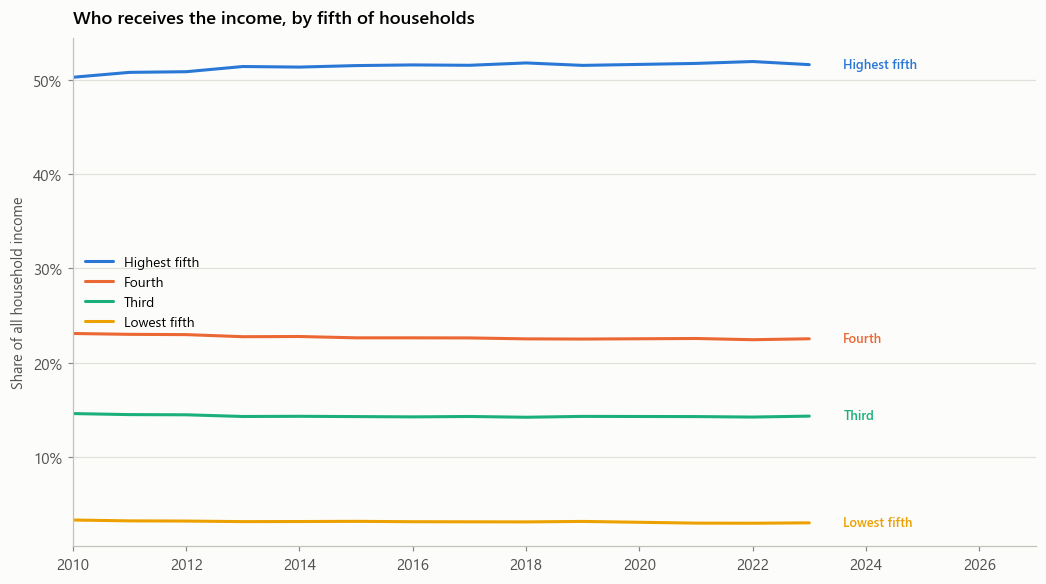

      Lowest fifth  Second  Third  Fourth  Highest fifth
2010          3.30    8.60  14.60   23.10          50.30
2011          3.21    8.47  14.49   23.01          50.82
2012          3.19    8.48  14.47   22.98          50.89
2013          3.13    8.38  14.29   22.76          51.44
2014          3.14    8.39  14.31   22.78          51.38
2015          3.16    8.39  14.28   22.64          51.54
2016          3.12    8.38  14.25   22.64          51.61
2017          3.11    8.40  14.29   22.63          51.57
2018          3.10    8.35  14.21   22.53          51.82
2019          3.15    8.48  14.30   22.51          51.56
2021          2.97    8.40  14.28   22.57          51.77
2022          2.96    8.40  14.23   22.44          51.97
2023          3.00    8.50  14.33   22.54          51.64


In [8]:
YEARS = [y for y in range(2010, ACS_YEAR + 1) if y != 2020]   # no ACS 1-year for 2020
quint = {}
for y in YEARS:
    try:
        d = sl.census_timeseries(ACS_URL % y, {"get": "group(B19082)", "for": "us:1"},
                                 CENSUS, cache_dir=DIRS["data"], tag="b19082_%d" % y)
        vals = [float(d.iloc[0]["B19082_%03dE" % i]) for i in range(1, 6)]
        quint[y] = vals
    except Exception as e:
        print("  %d unavailable (%s)" % (y, str(e)[:60]))

if quint:
    Q = pd.DataFrame(quint, index=["Lowest fifth", "Second", "Third", "Fourth",
                                   "Highest fifth"]).T
    fig, ax = plt.subplots(figsize=(9.4, 5.2))
    for name, color in zip(["Highest fifth", "Fourth", "Third", "Lowest fifth"],
                           sl.PALETTE[:4]):
        ax.plot(Q.index, Q[name].values, color=color, lw=2.0, label=name)
        sl.label_last(ax, Q[name], name, color, fontsize=8.5)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: "%.0f%%" % v))
    ax.set_ylabel("Share of all household income")
    ax.set_xlim(Q.index.min(), Q.index.max() + 4)
    ax.set_title("Who receives the income, by fifth of households")
    ax.legend(loc="center left")
    sl.save_fig(fig, "fig4_quintile_shares", DIRS)
    plt.show()
    print(Q.round(2).to_string())
else:
    Q = None
    print("No quintile data resolved; skipping Figure 4.")

## Figure 5 - Is the spread between jobs or inside them?

The superstar mechanism predicts widening dispersion among people doing
nominally the same work, not merely between occupations. The ratio of the 90th
to the 10th percentile of weekly earnings is the crude version of that test.
Every series is title-verified before use.

In [9]:
print("resolving wage percentiles:")
pct = {}
for label, cands, expect in [
    ("10th percentile", ["LEU0252911200Q", "LEU0252911300Q"], ["first decile", "earnings"]),
    ("Median", ["LEU0252881500Q"], ["median", "earnings"]),
    ("90th percentile", ["LEU0252911600Q", "LEU0252911700Q"], ["ninth decile", "earnings"]),
]:
    try:
        sid, title, s = sl.fred_resolve(cands, label, expect, FRED, cache_dir=DIRS["data"])
        pct[label] = sl.to_annual(s)
    except Exception as e:
        print("  %-30s unavailable: %s" % (label, str(e)[:110]))

if len(pct) >= 2 and "90th percentile" in pct and "10th percentile" in pct:
    common = pct["90th percentile"].dropna().index.intersection(pct["10th percentile"].dropna().index)
    ratios = pd.DataFrame({"90 / 10": pct["90th percentile"].loc[common] / pct["10th percentile"].loc[common]})
    if "Median" in pct:
        ratios["90 / 50"] = pct["90th percentile"].loc[common] / pct["Median"].loc[common]
        ratios["50 / 10"] = pct["Median"].loc[common] / pct["10th percentile"].loc[common]
    fig, ax = plt.subplots(figsize=(9.4, 5.2))
    for name, color in zip(ratios.columns, sl.PALETTE[:3]):
        ax.plot(ratios.index, ratios[name].values, color=color, lw=2.0, label=name)
        sl.label_last(ax, ratios[name], name, color)
    ax.set_ylabel("Ratio of weekly earnings")
    ax.set_xlim(ratios.index.min(), ratios.index.max() + 5)
    ax.set_title("Wage dispersion among full-time workers")
    ax.legend(loc="center left")
    sl.save_fig(fig, "fig5_wage_dispersion", DIRS)
    plt.show()
    print(ratios.round(3).to_string())
else:
    ratios = None
    print("Not enough percentile series resolved; skipping Figure 5.")

resolving wage percentiles:
FRED LEU0252911200Q: 105 obs, 2000-01-01-2026-04-01
  10th percentile                LEU0252911200Q       Employed full time: Usual weekly nominal earnings (first decile): Wage and salary workers: 16 years and over
   dropped partial year(s) [2025, 2026] (had [3, 2] of 4 observations)
FRED LEU0252881500Q: 189 obs, 1979-01-01-2026-04-01
  Median                         LEU0252881500Q       Employed full time: Median usual weekly nominal earnings (second quartile): Wage and salary workers: 16 years and over
   dropped partial year(s) [2025, 2026] (had [3, 2] of 4 observations)
FRED LEU0252911600Q: 105 obs, 2000-01-01-2026-04-01
  90th percentile                LEU0252911600Q       Employed full time: Usual weekly nominal earnings (first decile): Wage and salary workers: 16 years and over: Men
  90th percentile                unavailable: Series LEU0252911600Q is titled 'Employed full time: Usual weekly nominal earnings (first decile): Wage and sa
Not enough pe

## 2. Bank the numbers

In [10]:
payload = {
    "stacklib_version": sl.__version__,
    "acs_year": int(ACS_YEAR),
    "households": float(total),
    "lognormal_fit": {"mu": float(mu), "sigma": float(sigma),
                      "implied_median": float(np.exp(mu)), "sse": float(best_err)},
    "pareto_tail": {"fitted_above": TAIL_FROM, "alpha": float(alpha),
                    "r2": float(r2), "points": int(mask.sum())},
    "power_law_benchmark": {"lognormal_r2_on_same_test": float(syn_r2),
                            "lognormal_apparent_alpha": float(-syn_slope),
                            "real_beats_benchmark_by_r2": float(r2 - syn_r2)},
    "tail_predictions": {("$%d" % t): {"power_law": float(p), "log_normal": float(l)}
                         for t, p, l in zip(THRESHOLDS, pareto_pred, lognorm_pred)},
    "bracket_table": tab.replace({np.inf: None}).to_dict(orient="records"),
    "quintile_shares": (None if Q is None else Q.round(3).to_dict(orient="index")),
    "wage_dispersion": (None if ratios is None else
                        {"first_year": int(ratios.index[0]), "last_year": int(ratios.index[-1]),
                         "first": ratios.iloc[0].round(3).to_dict(),
                         "last": ratios.iloc[-1].round(3).to_dict()}),
}
sl.write_findings(payload, DIRS)
tab.to_csv(pathlib.Path(DIRS["findings"]) / "income_brackets.csv", index=False)
if Q is not None:
    Q.to_csv(pathlib.Path(DIRS["findings"]) / "quintile_shares.csv")
print("\nDone. Figures in figures/, numbers in findings/.")

findings -> C:\Users\91838\Downloads\Stack_Article\07_stars_and_power_laws\findings\headline_numbers.json

Done. Figures in figures/, numbers in findings/.


## Caveats to carry into the prose

1. **The top bracket is open and the story is inside it.** ACS stops at
   $200,000. Every number in Figure 3 above that line is extrapolation from a
   fit, not a count of anybody. The honest sentence is about the *shape* the
   data support, not about how many millionaires exist.
2. **A straight line on log-log axes is necessary, not sufficient.** The
   benchmark cell measures exactly how insufficient: a log-normal, which is not
   a power law, scores about 0.98 on the same test over these brackets. Quote
   the comparison between the two R-squared values, never the power-law one
   alone. Establishing a power law properly needs the Clauset, Shalizi and
   Newman procedure and far more tail resolution than a bracketed table gives.
3. **Households are not people and income is not earnings.** B19001 counts
   household money income before taxes and excludes capital gains, which is
   where a large share of top incomes actually appears.
4. **Grid-search fitting is not maximum likelihood.** The log-normal parameters
   minimise squared error on bracket probabilities. Good enough to show where
   the fit fails; not a publication-grade estimate.
5. **Wage percentiles cover full-time wage and salary workers only.** They
   exclude the self-employed and anyone paid mainly in equity, which is most of
   the population the chapter is about.

**Send back:** the five PNGs, the printed bracket table, the two fit lines
(log-normal parameters and Pareto alpha with its R-squared), the threshold
comparison, the quintile table, and `findings/headline_numbers.json`.